
# StockMini — AMD Stock Data Analysis

###  Project Overview
A beginner-friendly data analysis project using historical AMD stock market data.

**Objectives**
- Explore and understand stock market data
- Identify missing and invalid values
- Analyze daily stock returns
- Visualize stock prices and trading volume

---

## 1. Data Exploration

Explore dataset structure, data types, missing values, and duplicate records.

## 2. Data Cleaning

Detect invalid OHLC prices and handle missing opening prices.

## 3. Data Analysis

Calculate descriptive statistics and daily returns.

## 4. Data Visualization

Visualize stock price trends, trading volume, and daily return distribution.


In [3]:
import pandas as pd

In [4]:
df = pd.read_csv('AMD_stock_data.csv')

In [5]:
df.isna().sum() #check NaN in data set

Date         0
Open         0
High         0
Low          0
Close        0
Adj Close    0
Volume       0
dtype: int64

In [6]:
df

,Date,Open,High,Low,Close,Adj Close,Volume
0,1980-03-17,0.000000,3.302083,3.125000,3.145833,3.145833,219600
1,1980-03-18,0.000000,3.125000,2.937500,3.031250,3.031250,727200
2,1980-03-19,0.000000,3.083333,3.020833,3.041667,3.041667,295200
3,1980-03-20,0.000000,3.062500,3.010417,3.010417,3.010417,159600
4,1980-03-21,0.000000,3.020833,2.906250,2.916667,2.916667,130800
...,...,...,...,...,...,...,...
11157,2024-06-18,156.990005,157.240005,153.339996,154.630005,154.630005,51852000
11158,2024-06-20,155.820007,166.820007,155.500000,161.779999,161.779999,93245700
11159,2024-06-21,161.750000,163.199997,157.889999,161.229996,161.229996,61334700
11160,2024-06-24,159.750000,163.399994,158.190002,160.250000,160.250000,45954100


In [7]:
df['Date'] = pd.to_datetime(df['Date'])

In [8]:
df_datetime_index = df.set_index('Date')

In [9]:
df_datetime_index.duplicated().sum() #check data ที่ซ้ำ

np.int64(0)

In [10]:
df_datetime_index.index.min() , df_datetime_index.index.max()

(Timestamp('1980-03-17 00:00:00'), Timestamp('2024-06-25 00:00:00'))

In [11]:
df_datetime_index.index.duplicated().sum() #check วันที่ซ้ำ

np.int64(0)

In [12]:
df_datetime_index.dtypes

Open         float64
High         float64
Low          float64
Close        float64
Adj Close    float64
Volume         int64
dtype: object

In [13]:
(df_datetime_index['High'] < df_datetime_index['Low']).sum()
#check ว่ามี max ไหนมั้ยที่มีค่า น้อยกว่า min

np.int64(0)

In [14]:
print("High < Open:", (df_datetime_index["High"] < df_datetime_index["Open"]).sum())

print("High < Close:", (df_datetime_index["High"] < df_datetime_index["Close"]).sum())

print("Low > Open:", (df_datetime_index["Low"] > df_datetime_index["Open"]).sum())

print("Low > Close:", (df_datetime_index["Low"] > df_datetime_index["Close"]).sum())

High < Open: 0
High < Close: 0
Low > Open: 760
Low > Close: 0


In [15]:
#ตรวจสอบเงื่อนไข Low > Open
problem = df_datetime_index[
    df_datetime_index['Low'] > df_datetime_index['Open']
]

In [16]:
problem.head(10)

,Open,High,Low,Close,Adj Close,Volume
Date,,,,,,
1980-03-17,0.0,3.302083,3.125000,3.145833,3.145833,219600
1980-03-18,0.0,3.125000,2.937500,3.031250,3.031250,727200
1980-03-19,0.0,3.083333,3.020833,3.041667,3.041667,295200
1980-03-20,0.0,3.062500,3.010417,3.010417,3.010417,159600
1980-03-21,0.0,3.020833,2.906250,2.916667,2.916667,130800
1980-03-24,0.0,2.916667,2.635417,2.666667,2.666667,436800
1980-03-25,0.0,2.750000,2.552083,2.604167,2.604167,645600
1980-03-26,0.0,2.604167,2.427083,2.447917,2.447917,466800
1980-03-27,0.0,2.375000,2.239583,2.375000,2.375000,1129200


In [17]:
problem.index.min(), problem.index.max() #check วันที่มีปํญหา

(Timestamp('1980-03-17 00:00:00'), Timestamp('1983-03-18 00:00:00'))

In [18]:
df_datetime_index.loc[
    "1980-03-17":"1983-03-18", "Open"
].value_counts()

Open
0.0000    760
4.4375      1
Name: count, dtype: int64

In [19]:
df_datetime_index.loc[
    "1980-03-17":"1983-03-18"
].shape

(761, 6)

In [20]:
import numpy as np

df_datetime_index.loc[
    df_datetime_index['Open'] == 0, "Open"
] = np.nan

In [21]:
df_datetime_index.isna().sum()

Open         760
High           0
Low            0
Close          0
Adj Close      0
Volume         0
dtype: int64

In [22]:
(df_datetime_index["Low"] > df_datetime_index['Open']).sum()

np.int64(0)

In [23]:
df_datetime_index.describe()

,Open,High,Low,Close,Adj Close,Volume
count,10402.000000,11162.000000,11162.000000,11162.000000,11162.000000,1.116200e+04
mean,20.949111,20.233245,19.384932,19.813333,19.813333,1.941167e+07
std,30.188239,30.027673,28.822377,29.438539,29.438539,2.876606e+07
min,1.620000,1.690000,1.610000,1.620000,1.620000,0.000000e+00
25%,6.212500,5.560625,5.270208,5.410000,5.410000,1.287900e+06
50%,11.062500,10.312500,9.900000,10.090000,10.090000,7.283800e+06
75%,17.400000,17.062500,16.375000,16.717499,16.717499,2.481242e+07
max,213.410004,227.300003,208.220001,211.380005,211.380005,3.250584e+08


In [24]:
df_analysis = df_datetime_index.sort_index().copy()

In [25]:
df_analysis["Daily Return (%)"] = (
    df_analysis["Close"].pct_change(fill_method=None) * 100
)

df_analysis[["Close", "Daily Return (%)"]].head(10)

,Close,Daily Return (%)
Date,,
1980-03-17,3.145833,NaN
1980-03-18,3.031250,-3.642374
1980-03-19,3.041667,0.343653
1980-03-20,3.010417,-1.027397
1980-03-21,2.916667,-3.114187
1980-03-24,2.666667,-8.571428
1980-03-25,2.604167,-2.343750
1980-03-26,2.447917,-5.999999
1980-03-27,2.375000,-2.978736


# หาค่าทางสถิติ

In [27]:
returns = df_analysis["Daily Return (%)"].dropna()

print("Average Return:", returns.mean())
print("Maximum Return:", returns.max())
print("Minimum Return:", returns.min())
print("Volatility (Std):", returns.std())

Average Return: 0.10485547001050807
Maximum Return: 52.29008335186689
Minimum Return: -37.93103448275862
Volatility (Std): 3.7298957202707665


In [28]:
import matplotlib.pyplot as plt

# Data Visualization

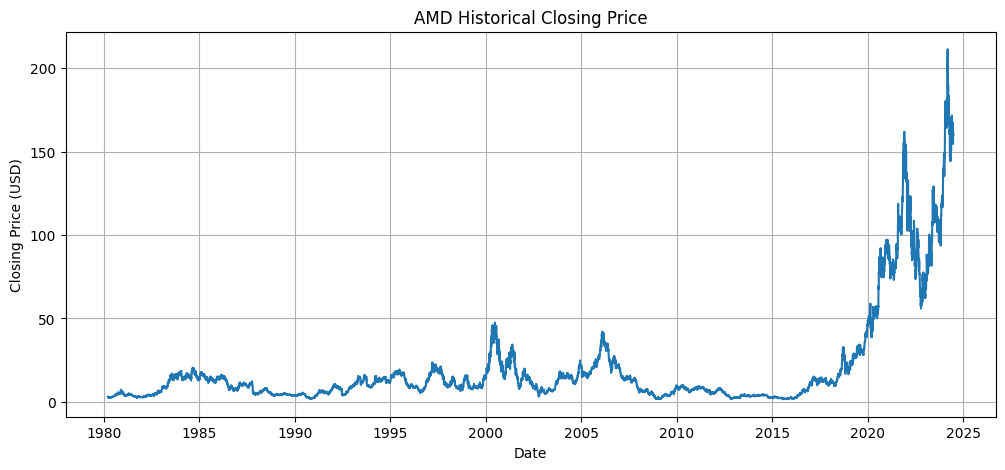

In [33]:
plt.figure(figsize=(12, 5))
plt.plot(
    df_analysis.index,
    df_analysis["Close"]
)

plt.title("AMD Historical Closing Price")
plt.xlabel("Date")
plt.ylabel("Closing Price (USD)")
plt.grid(True)

plt.show()